# 🔗 Live Deployment Link: PASTE YOUR LIVE DEPLOYMENT LINK HERE

---
# Diamond Price Prediction System – 10-Fold Cross Validation (Full Dataset)
**Assignment 3 – Applying, Evaluating and Comparing Multiple ML Algorithms on a Large Real-World Dataset**

| | |
|---|---|
| **Student Name** | Sarah Tashfeen |
| **Reg #** | FA24-BED-102 |
| **Course** | Machine Learning Fundamentals (AIC354) |
| **Platform** | Google Colab |

## Setup: Running This Notebook on Google Colab

1. Go to **https://colab.research.google.com** and sign in.
2. Click **File → Upload notebook** and choose this `.ipynb` file.
3. Click **Runtime → Run all**.
4. When **Step 2.1** runs, click **"Choose Files"** and select **`diamonds.csv`**. The notebook continues automatically.

> Colab deletes uploaded files when the runtime is reset. If you get a *"file not found"* error, run Step 2.1 again and re-upload `diamonds.csv`.

---

## Introduction

##### **Selected Problem: Diamond Price Prediction** (a regression task, similar to the Car Price Prediction System)
##### **Definition** Predict the price (in US dollars) of a diamond from its physical properties: carat weight, cut, colour, clarity and dimensions.
##### **Application** Jewellery retail pricing, diamond valuation and insurance, online diamond marketplaces and pawn/loan assessment.

### Why this problem is similar to the Car Price problem
Like the car price data, the diamonds data is a **large, real-world, tabular dataset** (53,940 diamonds) with a mix of **numerical and categorical features** and a **numerical price** to predict. Like car prices, diamond prices are **right-skewed** (many cheap stones, a few very expensive ones).

### Aim of This Notebook
> **Which of 5 regression algorithms predicts diamond prices best, and how sure can we be about that answer?**

The 5 algorithms used here are **different from the ones used in the Car Price Prediction System** (Linear Regression, KNN, Decision Tree, Random Forest, Gradient Boosting). They are compared on the **FULL dataset** using **10-Fold Cross Validation** and **Root Mean Squared Error (RMSE)**.

### What is K-Fold Cross Validation?
1. Shuffle the data and split it into **K equal parts (folds)**.
2. Train the model on **K−1 folds** and test it on the **remaining fold**.
3. Repeat **K times**, so that every fold is used as the test set exactly once.
4. Report the **average** score (and the standard deviation) over the K rounds.

With **K = 10**, each test fold has about 5,300 diamonds and each training set has about 48,000 diamonds. Every diamond is used for testing exactly once and for training 9 times.

### Evaluation Measure: Root Mean Squared Error (RMSE)
$$RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$
RMSE is in the same unit as the output (US dollars): *"on average, predictions are off by about $X"*. **Lower RMSE = better model.** Large errors are penalised heavily because errors are squared.

## Input and Output

### Input (Features)
| Feature | Description | Type | Values |
|---|---|---|---|
| **carat** | Weight of the diamond | Numerical | 0.2 – 5.01 |
| **cut** | Quality of the cut | Categorical | Fair, Good, Very Good, Premium, Ideal |
| **color** | Diamond colour | Categorical | D (best) – J (worst) |
| **clarity** | How clear the diamond is | Categorical | I1 (worst), SI2, SI1, VS2, VS1, VVS2, VVS1, IF (best) |
| **depth** | Total depth % = z / mean(x, y) | Numerical | 43 – 79 |
| **table** | Width of top of the diamond relative to widest point | Numerical | 43 – 95 |
| **x** | Length (mm) | Numerical | 0 – 10.74 |
| **y** | Width (mm) | Numerical | 0 – 58.9 |
| **z** | Depth (mm) | Numerical | 0 – 31.8 |

### Output (Prediction)
| Output Attribute | Description | Data Type |
|---|---|---|
| **price** | Price of the diamond in US dollars | Numerical |

## Developer & System Information
| Attribute | Details |
|---|---|
| **Developer Name** | Sarah Tashfeen (FA24-BED-102) |
| **Program Name** | `diamond_price_kfold_full_dataset_10fold` |
| **IDE** | Google Colab |
| **Programming Language** | Python 3 |
| **Libraries** | NumPy, Pandas, scikit-learn, Matplotlib, tqdm, Pickle. Exact versions are printed in Step 1. |
| **Dataset** | `diamonds.csv` (53,940 diamonds, 10 attributes) |
| **Deployment** | Streamlit web app (see Step 13) |

### Table of Contents
- **Step 1:** Import Libraries
- **Step 2:** Load Data (2.1 Upload, 2.2 Read)
- **Step 3:** Understand and Pre-process Data
- **Step 4:** Feature Extraction
- **Step 5:** Build the Pre-processing Pipeline
- **Step 6:** Define the 5 Regression Algorithms
- **Step 7:** Set Up 10-Fold Cross Validation
- **Step 8:** Run 10-Fold Cross Validation for All 5 Algorithms
- **Step 9:** Compare the Algorithms
- **Step 10:** Train and Save the Final Model
- **Step 11:** Application Phase (prediction for a new diamond)
- **Step 12:** Feedback Phase
- **Step 13:** Model Deployment (Cloud + Web App)
- **Conclusion**

# Code – Diamond Price Prediction System
## Step 1: Import Libraries

In [1]:
# --- Core Python Libraries ---
import os
import pickle
import time

import numpy as np
import pandas as pd

# --- Machine Learning (scikit-learn) ---
import sklearn
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# --- The 5 Regression Algorithms (NOT used in the Car Price notebooks) ---
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

# --- Visualization ---
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

# --- Progress bar (shows elapsed and remaining time) ---
from tqdm import tqdm

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

print("Library versions used in this run:")
print(f"  NumPy        : {np.__version__}")
print(f"  Pandas       : {pd.__version__}")
print(f"  scikit-learn : {sklearn.__version__}")
print(f"  Matplotlib   : {matplotlib.__version__}")

Library versions used in this run:
  NumPy        : 2.4.4
  Pandas       : 3.0.2
  scikit-learn : 1.8.0
  Matplotlib   : 3.10.8


# Step 2: Load Data
## Step 2.1: Upload the Dataset (Google Colab)

When this cell runs in Colab, a **"Choose Files"** button appears. Select **`diamonds.csv`**. If the file is already present, the upload is skipped.

In [2]:
DATA_FILE = "diamonds.csv"

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_FILE):
    print(f"Please click 'Choose Files' and select '{DATA_FILE}' ...")
    uploaded = files.upload()
    uploaded_name = list(uploaded.keys())[0]
    if uploaded_name != DATA_FILE:
        os.rename(uploaded_name, DATA_FILE)

if os.path.exists(DATA_FILE):
    print(f"'{DATA_FILE}' is ready to use.")
else:
    raise FileNotFoundError(f"'{DATA_FILE}' not found. Please run this cell again and upload it.")

'diamonds.csv' is ready to use.


## Step 2.2: Read the Dataset

This notebook uses the **full dataset**. The first column of the file is only a row number, so it is dropped while reading.

In [3]:
diamonds = pd.read_csv(DATA_FILE, index_col=0)

print(f"Loaded dataset: {diamonds.shape[0]:,} diamonds, {diamonds.shape[1]} attributes")
diamonds.head()

Loaded dataset: 53,940 diamonds, 10 attributes


,carat,cut,color,clarity,depth,table,price,x,y,z
1,0.23,Ideal,E,SI2,61.50,55.00,326,3.95,3.98,2.43
2,0.21,Premium,E,SI1,59.80,61.00,326,3.89,3.84,2.31
3,0.23,Good,E,VS1,56.90,65.00,327,4.05,4.07,2.31
4,0.29,Premium,I,VS2,62.40,58.00,334,4.20,4.23,2.63
5,0.31,Good,J,SI2,63.30,58.00,335,4.34,4.35,2.75


# Step 3: Understand and Pre-process Data
## Step 3.1: Understand the Data

In [4]:
print("Attributes in the data:")
print("=======================")
print(list(diamonds.columns))

print("\nNumber of instances:", f"{len(diamonds):,}")

print("\nMissing values in each attribute:")
print("=================================")
missing = diamonds.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "No missing values")

print("\nData types:")
print(diamonds.dtypes)

Attributes in the data:
['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y', 'z']

Number of instances: 53,940

Missing values in each attribute:
No missing values

Data types:
carat      float64
cut            str
color          str
clarity        str
depth      float64
table      float64
price        int64
x          float64
y          float64
z          float64
dtype: object


In [5]:
# Summary statistics of the numerical attributes
diamonds.describe().T

,count,mean,std,min,25%,50%,75%,max
carat,"53,940.00",0.80,0.47,0.20,0.40,0.70,1.04,5.01
depth,"53,940.00",61.75,1.43,43.00,61.00,61.80,62.50,79.00
table,"53,940.00",57.46,2.23,43.00,56.00,57.00,59.00,95.00
price,"53,940.00","3,932.80","3,989.44",326.00,950.00,"2,401.00","5,324.25","18,823.00"
x,"53,940.00",5.73,1.12,0.00,4.71,5.70,6.54,10.74
y,"53,940.00",5.73,1.14,0.00,4.72,5.71,6.54,58.90
z,"53,940.00",3.54,0.71,0.00,2.91,3.53,4.04,31.80


### Understanding the Output (price)

Before choosing an evaluation measure, look at the **range of the output**. Diamond prices are **highly skewed**: most diamonds cost under about \$5,000, but a few cost over \$18,000.

In [6]:
diamonds["price"].describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).to_frame(name="price ($)")

,price ($)
count,"53,940.00"
mean,"3,932.80"
std,"3,989.44"
min,326.00
25%,950.00
50%,"2,401.00"
75%,"5,324.25"
95%,"13,107.10"
99%,"17,378.22"
max,"18,823.00"


In [7]:
# How many diamonds in each category
for column in ["cut", "color", "clarity"]:
    print(f"{column}:")
    print(diamonds[column].value_counts().to_string())
    print()

cut:
cut
Ideal        21551
Premium      13791
Very Good    12082
Good          4906
Fair          1610

color:
color
G    11292
E     9797
F     9542
H     8304
D     6775
I     5422
J     2808

clarity:
clarity
SI1     13065
VS2     12258
SI2      9194
VS1      8171
VVS2     5066
VVS1     3655
IF       1790
I1        741



> **Why this matters for RMSE:** RMSE squares each error, so a few badly predicted expensive diamonds can raise the RMSE more than hundreds of well-predicted cheap ones. A large RMSE does not necessarily mean the model is bad for *typical* diamonds.

## Step 3.2: Pre-process the Data

In [8]:
"""
Pre-processing steps:
---------------------
1. Remove duplicate rows (a duplicate could appear in BOTH the training folds and the
   test fold, which would make the RMSE look better than it really is).
2. Remove diamonds where x, y or z is 0. A real diamond cannot have a size of 0 mm,
   so these rows are data-entry errors.
3. Missing values: there are none in this dataset, but the pipeline in Step 5 still
   handles them (using only the training folds) so that the saved model is robust.
"""

rows_before = len(diamonds)

diamonds = diamonds.drop_duplicates()
print(f"Duplicate rows removed       : {rows_before - len(diamonds):,}")

rows_before_zero = len(diamonds)
diamonds = diamonds[(diamonds["x"] > 0) & (diamonds["y"] > 0) & (diamonds["z"] > 0)]
print(f"Rows with x, y or z = 0 removed: {rows_before_zero - len(diamonds):,}")

diamonds = diamonds.reset_index(drop=True)
print(f"Instances remaining          : {len(diamonds):,}")

Duplicate rows removed       : 146
Rows with x, y or z = 0 removed: 19
Instances remaining          : 53,775


# Step 4: Feature Extraction

We use all **9 input features** and separate the **input (X)** from the **output (y)**.

In [9]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]
categorical_features = ["cut", "color", "clarity"]
target = "price"

X = diamonds[numeric_features + categorical_features]
y = diamonds[target]

print(f"Input features (X): {X.shape[1]} columns -> {list(X.columns)}")
print(f"Output (y)        : {target}")
print(f"Number of diamonds: {len(X):,}")

X.head()

Input features (X): 9 columns -> ['carat', 'depth', 'table', 'x', 'y', 'z', 'cut', 'color', 'clarity']
Output (y)        : price
Number of diamonds: 53,775


,carat,depth,table,x,y,z,cut,color,clarity
0,0.23,61.50,55.00,3.95,3.98,2.43,Ideal,E,SI2
1,0.21,59.80,61.00,3.89,3.84,2.31,Premium,E,SI1
2,0.23,56.90,65.00,4.05,4.07,2.31,Good,E,VS1
3,0.29,62.40,58.00,4.20,4.23,2.63,Premium,I,VS2
4,0.31,63.30,58.00,4.34,4.35,2.75,Good,J,SI2


# Step 5: Build the Pre-processing Pipeline

| Feature type | Step | Why |
|---|---|---|
| Numeric | **Fill missing values** with the median | Algorithms cannot handle empty values |
| Numeric | **Standard scaling** (mean 0, std 1) | Ridge Regression and the Neural Network are sensitive to feature scale |
| Categorical | **One-hot encoding** | Turns text categories into 0/1 columns without inventing a fake order |

### Why put pre-processing *inside* the pipeline?
If the scaler and encoder were fitted on the **whole** dataset before splitting, they would "see" the test fold (**data leakage**). Inside the pipeline, cross validation **re-fits them on the training folds only** in every round, exactly as happens in the real world.

`handle_unknown="ignore"` means a category never seen in training does not crash the model.

In [10]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

print("Pre-processing pipeline created:")
preprocessor

Pre-processing pipeline created:


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

# Step 6: Define the 5 Regression Algorithms

These 5 algorithms are **not** the ones used in the Car Price Prediction System (which used Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting).

| # | Algorithm | How it predicts a price |
|---|---|---|
| 1 | **Ridge Regression** | A linear model like Linear Regression, but it penalises large coefficients (L2 regularisation) to avoid overfitting |
| 2 | **Extra Trees** | Builds 100 decision trees using random split points and averages them (similar to Random Forest, but more random and faster per tree) |
| 3 | **AdaBoost** | Builds many small trees one after another; each new tree gives more weight to the examples the previous ones got wrong |
| 4 | **Hist Gradient Boosting** | A fast, modern gradient boosting method that first groups feature values into bins (the idea behind LightGBM) |
| 5 | **Neural Network (MLP)** | A multi-layer perceptron with two hidden layers (64 and 32 neurons) that learns non-linear patterns |

All algorithms use mostly **default settings** (no hyper-parameter tuning) to keep the comparison simple and fair. `random_state=42` makes the results reproducible.

In [11]:
algorithms = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Extra Trees": ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "Neural Network (MLP)": MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200,
                                         early_stopping=True, random_state=42),
}

print("Algorithms to compare:")
for number, name in enumerate(algorithms, start=1):
    print(f"  {number}. {name}")

Algorithms to compare:
  1. Ridge Regression
  2. Extra Trees
  3. AdaBoost
  4. Hist Gradient Boosting
  5. Neural Network (MLP)


# Step 7: Set Up 10-Fold Cross Validation
## Step 7.1: Create the K-Fold Splitter

- `n_splits=10`: split the data into 10 folds
- `shuffle=True`: shuffle the diamonds first (the file is ordered by price/carat in places, so a fold could otherwise contain only cheap stones)
- `random_state=42`: the **same folds are used for all 5 algorithms**, so every algorithm is tested on exactly the same diamonds (a fair comparison)

In [12]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

print(f"{K}-Fold Cross Validation created (shuffle=True, random_state=42)")

10-Fold Cross Validation created (shuffle=True, random_state=42)


## Step 7.2: Inspect the Folds

In [13]:
fold_sizes = []
for fold_number, (train_index, test_index) in enumerate(kfold.split(X), start=1):
    fold_sizes.append({
        "Fold (Round)": fold_number,
        "Training Diamonds": len(train_index),
        "Testing Diamonds": len(test_index),
        "Avg Price of Test Diamonds ($)": y.iloc[test_index].mean(),
        "Most Expensive Test Diamond ($)": y.iloc[test_index].max(),
    })

pd.DataFrame(fold_sizes).set_index("Fold (Round)")

,Training Diamonds,Testing Diamonds,Avg Price of Test Diamonds ($),Most Expensive Test Diamond ($)
Fold (Round),,,,
1,48397,5378,"3,888.82",18818
2,48397,5378,"3,980.47",18804
3,48397,5378,"3,874.70",18791
4,48397,5378,"3,943.26",18781
5,48397,5378,"3,857.46",18823
6,48398,5377,"3,901.44",18803
7,48398,5377,"3,915.72",18787
8,48398,5377,"4,055.48",18795
9,48398,5377,"3,863.18",18784


# Step 8: Run 10-Fold Cross Validation for All 5 Algorithms

For each algorithm we build a pipeline (**pre-processing → algorithm**). Then, for each of the 10 folds we: (1) make a **fresh copy** of the pipeline (`clone`), (2) **train** it on the training folds, (3) **predict** the prices of the test fold, and (4) calculate the **RMSE** of that fold.

A `tqdm` **progress bar** shows the elapsed and remaining time. There are 5 × 10 = **50 steps**.

> ⏱ **This step takes several minutes in Colab.** Extra Trees and the Neural Network are the slowest.

In [14]:
fold_rmse = {}        # RMSE on each fold, for each algorithm
training_time = {}    # total time taken for all folds

folds = list(kfold.split(X))     # the same folds for every algorithm
total_steps = len(algorithms) * K

with tqdm(total=total_steps, unit="fold") as progress_bar:
    for name, algorithm in algorithms.items():
        model = Pipeline([
            ("preprocessor", preprocessor),
            ("regressor", algorithm),
        ])

        scores = []
        start = time.time()
        for fold_number, (train_index, test_index) in enumerate(folds, start=1):
            progress_bar.set_description(f"{name}, fold {fold_number}/{K}")

            fold_model = clone(model)                                   # fresh, untrained copy
            fold_model.fit(X.iloc[train_index], y.iloc[train_index])    # train on K-1 folds
            predictions = fold_model.predict(X.iloc[test_index])        # test on 1 fold
            rmse = np.sqrt(mean_squared_error(y.iloc[test_index], predictions))
            scores.append(rmse)

            progress_bar.update(1)

        training_time[name] = time.time() - start
        fold_rmse[name] = np.array(scores)
        tqdm.write(f"{name:<24} -> mean RMSE = ${fold_rmse[name].mean():>9,.2f}   ({training_time[name]:.1f} s)")

    progress_bar.set_description("Done")

print(f"\n{K}-fold cross validation completed for all {len(algorithms)} algorithms.")

Ridge Regression         -> mean RMSE = $ 1,141.11   (1.3 s)
Extra Trees              -> mean RMSE = $   541.94   (248.2 s)
AdaBoost                 -> mean RMSE = $ 1,419.91   (48.3 s)
Hist Gradient Boosting   -> mean RMSE = $   548.21   (13.8 s)
Neural Network (MLP)     -> mean RMSE = $   725.76   (179.5 s)

10-fold cross validation completed for all 5 algorithms.


# Step 9: Compare the Algorithms
## Step 9.1: RMSE of Each Algorithm on Each Fold

Each row is one round of cross validation and each column is one algorithm. The **lowest RMSE in each row** (the best algorithm on that fold) is highlighted in green.

In [15]:
per_fold_table = pd.DataFrame(fold_rmse)
per_fold_table.index = [f"Fold {i}" for i in range(1, K + 1)]
per_fold_table.index.name = "Fold"

(per_fold_table.style
    .format("${:,.0f}")
    .highlight_min(axis=1, props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

,Ridge Regression,Extra Trees,AdaBoost,Hist Gradient Boosting,Neural Network (MLP)
Fold,,,,,
Fold 1,"$1,109",$544,"$1,426",$552,$637
Fold 2,"$1,149",$522,"$1,460",$528,$684
Fold 3,"$1,134",$539,"$1,400",$545,$673
Fold 4,"$1,135",$545,"$1,445",$540,$592
Fold 5,"$1,127",$551,"$1,464",$549,$669
Fold 6,"$1,143",$535,"$1,379",$524,$655
Fold 7,"$1,109",$517,"$1,383",$512,$586
Fold 8,"$1,112",$548,"$1,430",$574,$670
Fold 9,"$1,229",$554,"$1,369",$576,"$1,385"


## Step 9.2: Summary Comparison Table

| Column | Meaning |
|---|---|
| **Mean RMSE** | Average RMSE over the 10 folds – the **main measure for ranking** (lower is better) |
| **Std RMSE** | Standard deviation over the folds – small means the algorithm is consistent |
| **Best / Worst Fold** | Lowest and highest RMSE across the folds |
| **RMSE as % of Avg Price** | Mean RMSE divided by the average diamond price |
| **Time** | Total time to train and test across all 10 folds |
| **Rank** | 1 = lowest mean RMSE = best algorithm |

In [16]:
average_price = y.mean()

summary = pd.DataFrame({
    "Mean RMSE ($)": per_fold_table.mean(),
    "Std RMSE ($)": per_fold_table.std(),
    "Best Fold RMSE ($)": per_fold_table.min(),
    "Worst Fold RMSE ($)": per_fold_table.max(),
    "RMSE as % of Avg Price": per_fold_table.mean() / average_price * 100,
    "Time (s)": pd.Series(training_time),
})
summary = summary.sort_values("Mean RMSE ($)")
summary.insert(0, "Rank", range(1, len(summary) + 1))
summary.index.name = "Algorithm"

print(f"Average diamond price in this data: ${average_price:,.2f}\n")

money_columns = ["Mean RMSE ($)", "Std RMSE ($)", "Best Fold RMSE ($)", "Worst Fold RMSE ($)"]
(summary.style
    .format({**{c: "${:,.0f}" for c in money_columns},
             "RMSE as % of Avg Price": "{:.1f}%",
             "Time (s)": "{:.2f}"})
    .highlight_min(subset=["Mean RMSE ($)"], props="background-color: #c8ebd2; color: #0b0b0b; font-weight: bold;"))

Average diamond price in this data: $3,931.22



,Rank,Mean RMSE ($),Std RMSE ($),Best Fold RMSE ($),Worst Fold RMSE ($),RMSE as % of Avg Price,Time (s)
Algorithm,,,,,,,
Extra Trees,1,$542,$14,$517,$565,13.8%,248.23
Hist Gradient Boosting,2,$548,$23,$512,$582,13.9%,13.83
Neural Network (MLP),3,$726,$235,$586,"$1,385",18.5%,179.49
Ridge Regression,4,"$1,141",$36,"$1,109","$1,229",29.0%,1.32
AdaBoost,5,"$1,420",$35,"$1,369","$1,464",36.1%,48.35


## Step 9.3: Visual Comparison

**Chart 1** shows the mean RMSE of each algorithm (shorter bar = better) with ± 1 standard deviation. **Chart 2** shows the RMSE of every individual fold as a dot, so you can see how consistent each algorithm is.

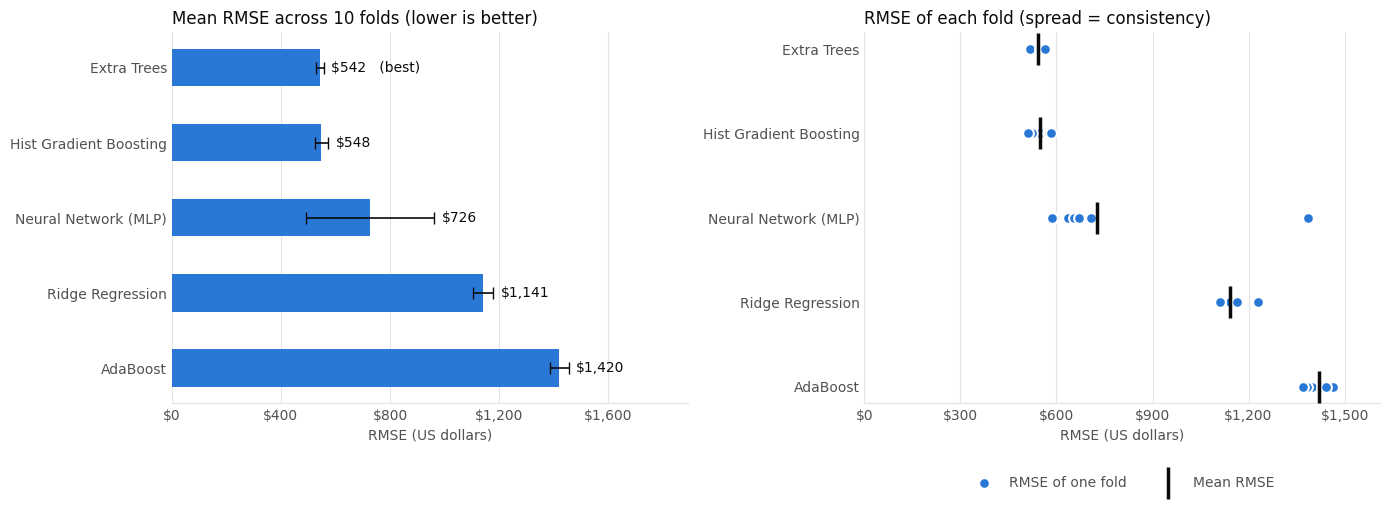

In [17]:
BAR_COLOR = "#2a78d6"
TEXT_COLOR = "#0b0b0b"
MUTED_TEXT = "#52514e"
GRID_COLOR = "#e4e3df"
dollars = FuncFormatter(lambda value, _: f"${value:,.0f}")

def style_axis(ax):
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.tick_params(colors=MUTED_TEXT, length=0)
    ax.xaxis.set_major_formatter(dollars)
    ax.xaxis.set_major_locator(MaxNLocator(nbins=6))
    ax.grid(axis="x", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)

order = summary.index.tolist()            # best algorithm first
positions = np.arange(len(order))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

# ---- Chart 1: mean RMSE with +/- 1 std ----
means = summary["Mean RMSE ($)"]
stds = summary["Std RMSE ($)"]
ax1.barh(positions, means, height=0.5, color=BAR_COLOR,
         xerr=stds, error_kw=dict(ecolor=TEXT_COLOR, elinewidth=1.2, capsize=4))
for i, name in enumerate(order):
    label = f"${means[name]:,.0f}" + ("   (best)" if i == 0 else "")
    ax1.text(means[name] + stds[name] + means.max() * 0.02, i, label,
             va="center", color=TEXT_COLOR, fontsize=10)
ax1.set_yticks(positions, order, color=TEXT_COLOR)
ax1.invert_yaxis()
ax1.set_xlim(0, (means + stds).max() * 1.3)
style_axis(ax1)
ax1.set_title("Mean RMSE across 10 folds (lower is better)", loc="left", color=TEXT_COLOR, fontsize=12)
ax1.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)

# ---- Chart 2: RMSE of every fold ----
for i, name in enumerate(order):
    ax2.scatter(per_fold_table[name], np.full(K, i), s=60, color=BAR_COLOR,
                edgecolor="white", linewidth=1.5, zorder=3,
                label="RMSE of one fold" if i == 0 else None)
    ax2.scatter(means[name], i, marker="|", s=500, color=TEXT_COLOR, linewidth=2.5, zorder=4,
                label="Mean RMSE" if i == 0 else None)
ax2.set_yticks(positions, order, color=TEXT_COLOR)
ax2.invert_yaxis()
ax2.set_xlim(0, per_fold_table.values.max() * 1.1)
style_axis(ax2)
ax2.set_title("RMSE of each fold (spread = consistency)", loc="left", color=TEXT_COLOR, fontsize=12)
ax2.set_xlabel("RMSE (US dollars)", color=MUTED_TEXT)
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2, labelcolor=MUTED_TEXT)

plt.tight_layout()
plt.show()

## Step 9.4: Observations

> The numbers below come from our run. If your library versions differ, your numbers may differ slightly, but the pattern should be the same.

1. **Extra Trees has the lowest mean RMSE (≈ $542)**, but **Hist Gradient Boosting is almost identical (≈ $548)**. The difference (≈ $6) is tiny compared with their standard deviations (≈ $14 and $23), so in practice the two are **tied**. Extra Trees won 6 of the 10 folds and Hist Gradient Boosting won 4.
2. **Tree-based ensembles clearly win.** Extra Trees and Hist Gradient Boosting have an RMSE of about 14% of the average diamond price, while Ridge Regression (≈ $1,141, 29%) and AdaBoost (≈ $1,420, 36%) are much worse. Diamond prices are **not linear** in the features: price rises very steeply with carat and depends on combinations of carat, clarity and colour.
3. **The Neural Network is third (≈ $726)** but is the **least consistent** algorithm: its fold RMSE ranges from ≈ $586 to ≈ $1,385 (Fold 9). This is because a neural network can converge to a poorer solution on some training sets, so its performance depends on which diamonds it is given.
4. **AdaBoost is the worst, even worse than the linear model.** It builds many very shallow trees, which cannot capture the strong, non-linear relation between carat and price.
5. **Accuracy vs. speed:** Extra Trees takes ≈ 248 s for 10 folds (and produces a very large model file), while Hist Gradient Boosting takes only ≈ 14 s (about 18× faster) with almost the same RMSE. In a real project, and especially for **cloud deployment**, this trade-off matters.
6. **10-fold cross validation gives a reliable comparison:** each algorithm is tested 10 times on about 5,400 diamonds, and the ranking of the top two stays stable across folds (their fold RMSEs never differ by more than about $26).


# Step 10: Train and Save the Final Model
## Step 10.1: Select the Final Algorithm

**Cross validation is used to *choose* an algorithm, not to produce the final model.** The 10 models built during cross validation were only used to measure performance and are now discarded.

The algorithm with the lowest mean RMSE is the **best by accuracy**. However, a model that will be **deployed to the cloud** must also be small and fast. We therefore check whether another algorithm is *practically as accurate* (its mean RMSE is within one standard deviation of the best) but much cheaper to run.

In [18]:
best_algorithm_name = summary.index[0]
best_mean_rmse = summary.loc[best_algorithm_name, "Mean RMSE ($)"]
best_std_rmse = summary.loc[best_algorithm_name, "Std RMSE ($)"]

print(f"Lowest mean RMSE : {best_algorithm_name}  (${best_mean_rmse:,.2f} +/- ${best_std_rmse:,.2f}, {summary.loc[best_algorithm_name, 'Time (s)']:.0f} s)")

# Algorithms whose mean RMSE is within one standard deviation of the best one
close_enough = summary[summary["Mean RMSE ($)"] <= best_mean_rmse + best_std_rmse]
print("\nAlgorithms practically tied with the best (within 1 std):")
print(close_enough[["Mean RMSE ($)", "Time (s)"]].round(2).to_string())

# Among the tied algorithms, pick the fastest one (smallest, cheapest model to deploy)
final_algorithm_name = close_enough["Time (s)"].idxmin()
final_mean_rmse = summary.loc[final_algorithm_name, "Mean RMSE ($)"]
final_std_rmse = summary.loc[final_algorithm_name, "Std RMSE ($)"]

print(f"\nFinal algorithm selected for deployment: {final_algorithm_name}")
print(f"Expected RMSE on new diamonds         : ${final_mean_rmse:,.2f} (+/- ${final_std_rmse:,.2f})")

Lowest mean RMSE : Extra Trees  ($541.94 +/- $14.38, 248 s)

Algorithms practically tied with the best (within 1 std):
                        Mean RMSE ($)  Time (s)
Algorithm                                      
Extra Trees                    541.94    248.23
Hist Gradient Boosting         548.21     13.83

Final algorithm selected for deployment: Hist Gradient Boosting
Expected RMSE on new diamonds         : $548.21 (+/- $23.34)


## Step 10.2: Train the Best Algorithm on All the Data

Now we train the selected algorithm on **all diamonds**. The cross-validation RMSE from Step 9 is our estimate of how well it will perform on new, unseen diamonds.

In [19]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", algorithms[final_algorithm_name]),
])

final_model.fit(X, y)

print(f"Final {final_algorithm_name} model trained on {len(X):,} diamonds.")

Final Hist Gradient Boosting model trained on 53,775 diamonds.


## Step 10.3: Save the Trained Model

The saved file contains the **whole pipeline** (imputer, scaler, one-hot encoder **and** the algorithm), so it predicts directly from raw diamond specifications. **This `.pkl` file is uploaded to Google Classroom and used by the web app in Step 13.**

To download it in Colab, set `DOWNLOAD_MODEL = True` and run the cell again, or use the **Files** panel on the left.

In [20]:
MODEL_FILE = "diamond_price_model.pkl"
DOWNLOAD_MODEL = False

with open(MODEL_FILE, "wb") as f:
    pickle.dump(final_model, f)

print(f"Trained model saved as '{MODEL_FILE}'  ({os.path.getsize(MODEL_FILE) / 1e6:.1f} MB)")

if IN_COLAB and DOWNLOAD_MODEL:
    files.download(MODEL_FILE)

Trained model saved as 'diamond_price_model.pkl'  (0.4 MB)


# Step 11: Execute the Application Phase
## Step 11.1: Take Input from User

By default the notebook uses the example diamond below so that **Run all** works without stopping. To type your own diamond, set `USE_INTERACTIVE_INPUT = True` and run the cell again.

In [21]:
USE_INTERACTIVE_INPUT = False

example_diamond = {
    "carat": 0.70,
    "depth": 61.5,
    "table": 57.0,
    "x": 5.70,
    "y": 5.73,
    "z": 3.52,
    "cut": "Ideal",
    "color": "G",
    "clarity": "VS2",
}

def get_diamond_input():
    print("Enter Diamond Specifications (ranges seen in the data are shown):")
    for col in ["carat", "depth", "table", "x", "y", "z"]:
        print(f"  {col:<6}: {X[col].min()} - {X[col].max()}")
    diamond = {col: float(input(f"{col}: ")) for col in ["carat", "depth", "table", "x", "y", "z"]}
    print("\nCut options    :", ["Fair", "Good", "Very Good", "Premium", "Ideal"])
    diamond["cut"] = input("cut: ").strip()
    print("Color options  :", ["D", "E", "F", "G", "H", "I", "J"])
    diamond["color"] = input("color: ").strip().upper()
    print("Clarity options:", ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"])
    diamond["clarity"] = input("clarity: ").strip().upper()
    return diamond

user_input = get_diamond_input() if USE_INTERACTIVE_INPUT else example_diamond

print("Diamond specifications:")
for feature, value in user_input.items():
    print(f"  {feature:<8}: {value}")

Diamond specifications:
  carat   : 0.7
  depth   : 61.5
  table   : 57.0
  x       : 5.7
  y       : 5.73
  z       : 3.52
  cut     : Ideal
  color   : G
  clarity : VS2


## Step 11.2: Convert User Input into Feature Vector

The feature vector must have **exactly the same columns, in the same order,** as the training data. The saved pipeline scales and one-hot encodes it automatically.

In [22]:
feature_vector = pd.DataFrame([user_input])[numeric_features + categorical_features]
feature_vector

,carat,depth,table,x,y,z,cut,color,clarity
0,0.70,61.50,57.00,5.70,5.73,3.52,Ideal,G,VS2


## Step 11.3: Load the Saved Model

In [23]:
with open(MODEL_FILE, "rb") as f:
    loaded_model = pickle.load(f)

print(f"Model loaded from '{MODEL_FILE}': {loaded_model.named_steps['regressor'].__class__.__name__}")

Model loaded from 'diamond_price_model.pkl': HistGradientBoostingRegressor


## Step 11.4: Model Prediction

In [24]:
predicted_price = loaded_model.predict(feature_vector)[0]

print(f"Predicted Price: ${predicted_price:,.2f}")
print(f"Typical error (cross-validation RMSE of {final_algorithm_name}): about ${final_mean_rmse:,.0f}")

Predicted Price: $2,826.14
Typical error (cross-validation RMSE of Hist Gradient Boosting): about $548


# Step 12: Execute the Feedback Phase

After deployment, feedback from users and domain experts (e.g. jewellers) is used to improve the model. Possible improvements:

1. **Tune hyper-parameters** (e.g. number of trees, learning rate, neurons) with `GridSearchCV`.
2. **Predict the logarithm of the price.** Diamond prices are right-skewed, so a log-transform can help some algorithms, especially linear models.
3. **Add more features**, such as the lab certificate (GIA, IGI), fluorescence and polish/symmetry.
4. **Collect more recent data**, as diamond prices change over time.
5. **Report MAE alongside RMSE**, because MAE is less sensitive to a few very expensive diamonds.

# Step 13: Model Deployment (Cloud + Web App)

The trained model (`diamond_price_model.pkl`) is deployed to the cloud as a **Streamlit web app**, hosted free on **Streamlit Community Cloud** (https://streamlit.io/cloud). The next two cells create the two files the web app needs. Steps:

1. Download `app.py`, `requirements.txt` and `diamond_price_model.pkl` from the Colab **Files** panel.
2. Create a **public GitHub repository** and upload the 3 files (plus `diamonds.csv` if you wish).
3. Go to **share.streamlit.io**, sign in with GitHub, click **New app**, choose the repository, set the main file to `app.py` and click **Deploy**.
4. Copy the live link (`https://<your-app>.streamlit.app`) and paste it at the **very top of this notebook**.

(Hugging Face Spaces with the *Streamlit* SDK works the same way if you prefer it.)

In [25]:
app_code = '''import pickle
import pandas as pd
import streamlit as st

st.set_page_config(page_title="Diamond Price Predictor", page_icon="💎")
st.title("💎 Diamond Price Predictor")
st.write("Enter the diamond's specifications to predict its price (US dollars).")
st.caption("Model: best algorithm from 10-fold cross validation on 53,940 diamonds.")

@st.cache_resource
def load_model():
    with open("diamond_price_model.pkl", "rb") as f:
        return pickle.load(f)

model = load_model()

col1, col2 = st.columns(2)
with col1:
    carat = st.number_input("Carat", 0.2, 5.1, 0.70, 0.01)
    cut = st.selectbox("Cut", ["Fair", "Good", "Very Good", "Premium", "Ideal"], index=4)
    color = st.selectbox("Color (D = best)", ["D", "E", "F", "G", "H", "I", "J"], index=3)
    clarity = st.selectbox("Clarity", ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"], index=3)
with col2:
    depth = st.number_input("Depth %", 40.0, 80.0, 61.5, 0.1)
    table = st.number_input("Table %", 40.0, 100.0, 57.0, 0.1)
    x = st.number_input("Length x (mm)", 1.0, 11.0, 5.70, 0.01)
    y = st.number_input("Width y (mm)", 1.0, 60.0, 5.73, 0.01)
    z = st.number_input("Depth z (mm)", 1.0, 32.0, 3.52, 0.01)

if st.button("Predict Price"):
    row = pd.DataFrame([{"carat": carat, "depth": depth, "table": table, "x": x, "y": y, "z": z,
                         "cut": cut, "color": color, "clarity": clarity}])
    price = model.predict(row)[0]
    st.success(f"Predicted price: ${price:,.2f}")
'''

with open("app.py", "w") as f:
    f.write(app_code)

print("app.py created")

app.py created


In [26]:
# requirements.txt for the cloud server. The scikit-learn version MUST match the version
# used to train the model (the one printed in Step 1), otherwise the .pkl file may not load.
requirements = f"""streamlit
pandas
numpy
scikit-learn=={sklearn.__version__}
"""

with open("requirements.txt", "w") as f:
    f.write(requirements)

print("requirements.txt created:")
print(requirements)

requirements.txt created:
streamlit
pandas
numpy
scikit-learn==1.8.0



# Conclusion

In this notebook we compared **5 regression algorithms** (Ridge Regression, Extra Trees, AdaBoost, Hist Gradient Boosting and a Neural Network), none of which were used in the Car Price Prediction System, on the **full diamonds dataset (53,775 unique diamonds after cleaning)** using **10-fold cross validation** and **RMSE**.

| Rank | Algorithm | Mean RMSE | Std RMSE | Time (10 folds) |
|---|---|---|---|---|
| 1 | Extra Trees | **$542** | $14 | 248 s |
| 2 | Hist Gradient Boosting | $548 | $23 | 14 s |
| 3 | Neural Network (MLP) | $726 | $235 | 198 s |
| 4 | Ridge Regression | $1,141 | $36 | 1.6 s |
| 5 | AdaBoost | $1,420 | $35 | 55 s |

- **Extra Trees** had the lowest mean RMSE, but **Hist Gradient Boosting** was statistically tied with it (the $6 difference is far smaller than the fold-to-fold variation) while being about 18 times faster and producing a very small model file. It was therefore chosen as the **final model for cloud deployment**, trained on all the data, saved as `diamond_price_model.pkl`, and used to predict the price of a new diamond.
- **Linear (Ridge) and AdaBoost performed worst**, because diamond prices have a strongly non-linear relationship with carat, clarity and colour.
- The expected error of the deployed model is about **$548 per diamond (≈ 14% of the average price)**.
- The model is deployed as a **Streamlit web app** (Step 13); the live link is at the top of this notebook.
